In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from scipy.stats import norm
from scipy.optimize import brentq
from vol_surface.deribit import get_book_summary_by_currency


def build_market_df(currency="BTC", min_iv=1.0):
    data = get_book_summary_by_currency(currency, "option")
    now = datetime.now(timezone.utc)
    rows = []
    for d in data:
        mark_iv = d.get("mark_iv")
        F = d.get("underlying_price")
        price = d.get("mark_price")          # prezzo in BTC
        if not mark_iv or mark_iv < min_iv or not F or not price:
            continue

        _, exp_str, strike_str, cp = d["instrument_name"].split("-")
        K = float(strike_str)
        if (cp == "C" and K < F) or (cp == "P" and K >= F):
            continue

        expiry = datetime.strptime(exp_str, "%d%b%y").replace(hour=8, tzinfo=timezone.utc)
        T = (expiry - now).total_seconds() / (365 * 24 * 3600)
        if T <= 0:
            continue

        rows.append({"T": T, "m": K / F, "cp": cp, "price": price, "iv": mark_iv / 100})
    return pd.DataFrame(rows)


df = build_market_df("BTC")
print(len(df))
df.head()

480


,T,m,cp,price,iv
0,0.399196,1.315906,C,0.017483,0.3816
1,0.149881,2.180138,C,0.000180,0.6836
2,0.001936,0.976221,P,0.000139,0.2881
3,0.245771,1.148258,C,0.025432,0.3692
4,0.648511,0.811311,P,0.049985,0.4221


In [2]:
def bs_price(m, T, sigma, cp):
    """Prezzo in BTC (Black-76 con F=1, strike=m, tasso 0)."""
    sd = sigma * np.sqrt(T)
    d1 = (-np.log(m) + 0.5 * sd**2) / sd
    d2 = d1 - sd
    if cp == "C":
        return norm.cdf(d1) - m * norm.cdf(d2)
    return m * norm.cdf(-d2) - norm.cdf(-d1)


def implied_vol(price, m, T, cp):
    try:
        return brentq(lambda s: bs_price(m, T, s, cp) - price, 1e-4, 5.0)
    except ValueError:
        return np.nan


df["iv_inv"] = [implied_vol(p, m, T, cp)
                for p, m, T, cp in zip(df["price"], df["m"], df["T"], df["cp"])]
df["err"] = df["iv_inv"] - df["iv"]

print("IV non invertibili:", df["iv_inv"].isna().sum())
print(df["err"].abs().describe())

IV non invertibili: 0
count    4.800000e+02
mean     4.101780e-05
std      8.286693e-05
min      2.099895e-07
25%      1.343091e-05
50%      2.851022e-05
75%      4.330748e-05
max      1.303486e-03
Name: err, dtype: float64


Sigma Black-Scholes: 0.3843


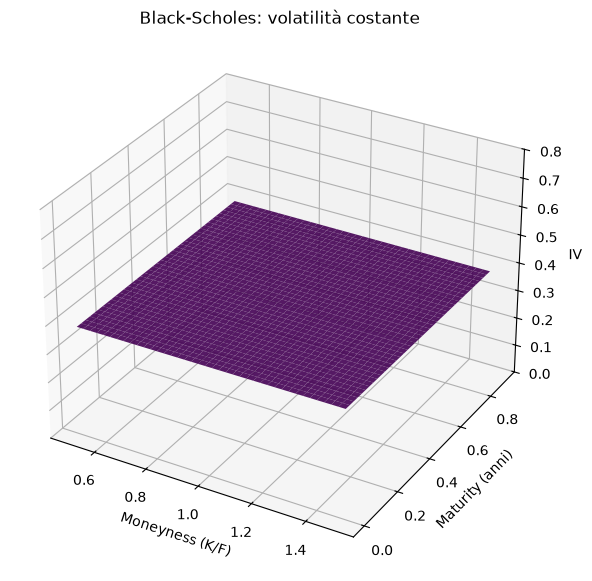

In [3]:
atm = df[(df["m"] > 0.95) & (df["m"] < 1.05)]
sigma_bs = atm["iv"].median()
print(f"Sigma Black-Scholes: {sigma_bs:.4f}")

m_grid = np.linspace(0.5, 1.5, 40)
T_grid = np.linspace(df["T"].min(), df["T"].max(), 40)
M, TT = np.meshgrid(m_grid, T_grid)
IV_bs = np.full_like(M, sigma_bs)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(M, TT, IV_bs, cmap="viridis", alpha=0.9)
ax.set_zlim(0, 0.8)
ax.set_xlabel("Moneyness (K/F)")
ax.set_ylabel("Maturity (anni)")
ax.set_zlabel("IV")
ax.set_title("Black-Scholes: volatilità costante")
plt.show()